# Etapa 1 — Análise exploratória (NSL-KDD modificado)

**Objetivo.** Antes de treinar qualquer modelo, precisamos *conhecer* os dados: o que há neles, o que está errado, o que é redundante e o que pode ser "trapaça" (vazamento). Este notebook faz esse diagnóstico e termina com uma tabela de **ações para o pré-processamento** (Etapa 2).

**Contexto.** Base de detecção de intrusão em redes (NSL-KDD) modificada pela professora para uma competição. Cada linha é uma conexão de rede; a classe `class` diz se ela é `normal` ou `anomaly`. A métrica oficial é o **F1-macro**.

**Regras que seguimos aqui**
- O **teste** (`teste_sem_rotulo.csv`) só é usado para *comparar características* (ausentes, valores inválidos, categorias). Nada é ajustado, imputado, escalado ou selecionado com base nele.
- Não usamos os arquivos originais do NSL-KDD para descobrir rótulos.
- Todo número citado nos textos vem de uma célula de código deste notebook.

**Roteiro:** 1 Caracterização · 2 Classes · 3 Categóricos · 4 Inconsistências · 5 Redundâncias · 6 Vazamentos · 7 Diagnóstico final.

## 0. Configuração e carga dos dados

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score

SEED = 42                      # semente fixa: o notebook é reprodutível
np.random.seed(SEED)
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"   # paleta simples e distinguível

PASTA = Path("BANCO_DE_DADOS")
treino = pd.read_csv(PASTA / "treino.csv")
teste = pd.read_csv(PASTA / "teste_sem_rotulo.csv")

ALVO = "class"
CAT = ["protocol_type", "service", "flag", "tipo_alerta_soc"]          # colunas de texto (features)
NOVAS = ["src_bytes_kb", "dst_bytes_kb", "total_bytes", "same_srv_pct", "protocolo_cod",
         "score_ids_legado", "tipo_alerta_soc", "tempo_resposta_analista_min"]  # 8 colunas acrescentadas
NUM = [c for c in treino.columns if c not in CAT + [ALVO]]             # colunas numéricas
TAXAS = [c for c in NUM if c.endswith("_rate")]                        # taxas (devem estar em [0, 1])

y = (treino[ALVO] == "anomaly").astype(int)    # 1 = anomaly, 0 = normal (só para análise)
R = {}                                         # dicionário onde guardamos números para o diagnóstico final

print("treino:", treino.shape, "| teste:", teste.shape)
print("Colunas só no treino:", sorted(set(treino.columns) - set(teste.columns)))
print("Colunas só no teste :", sorted(set(teste.columns) - set(treino.columns)))

treino: (69833, 50) | teste: (24333, 50)
Colunas só no treino: ['class']
Colunas só no teste : ['id']


## 1. Caracterização dos dados

Primeiro, o básico: quantas linhas e colunas, de que tipo é cada coluna e **onde faltam valores**. Valores ausentes (NaN) precisam de tratamento antes de quase qualquer modelo, e saber *quanto* e *onde* falta decide a estratégia (imputar, descartar a coluna, criar um indicador de ausência).

In [2]:
# Tamanho e tipos
resumo = pd.DataFrame({
    "linhas": [len(treino), len(teste)],
    "colunas": [treino.shape[1], teste.shape[1]],
    "numéricas": [treino.select_dtypes("number").shape[1], teste.select_dtypes("number").shape[1]],
    "texto": [treino.select_dtypes(exclude="number").shape[1], teste.select_dtypes(exclude="number").shape[1]],
    "linhas com ≥1 ausente": [treino.isna().any(axis=1).sum(), teste.isna().any(axis=1).sum()],
}, index=["treino", "teste"])
display(resumo)

print("Colunas de texto no treino:", list(treino.select_dtypes(exclude="number").columns))
print("Colunas de texto no teste :", list(teste.select_dtypes(exclude="number").columns))
print("\nTipos numéricos (treino):")
print(treino.select_dtypes("number").dtypes.value_counts().to_string())

,linhas,colunas,numéricas,texto,linhas com ≥1 ausente
treino,69833,50,45,5,69512
teste,24333,50,46,4,24224


Colunas de texto no treino: ['protocol_type', 'service', 'flag', 'tipo_alerta_soc', 'class']
Colunas de texto no teste : ['protocol_type', 'service', 'flag', 'tipo_alerta_soc']

Tipos numéricos (treino):
float64    32
int64      13


,treino_n,treino_%,teste_n,teste_%
tempo_resposta_analista_min,63804,91.3665,22533,92.6026
src_bytes,27906,39.9610,9859,40.5170
src_bytes_kb,27906,39.9610,9859,40.5170
total_bytes,27906,39.9610,9859,40.5170
dst_host_srv_count,27844,39.8723,9567,39.3170
dst_host_serror_rate,21393,30.6345,7356,30.2306
dst_host_same_src_port_rate,19543,27.9853,6848,28.1429
serror_rate,4734,6.7790,1630,6.6987
service,4416,6.3237,1528,6.2795
logged_in,4250,6.0859,1444,5.9343


Colunas com ausentes no treino: 28 | no teste: 28
Maior diferença treino x teste (pontos percentuais): 1.24


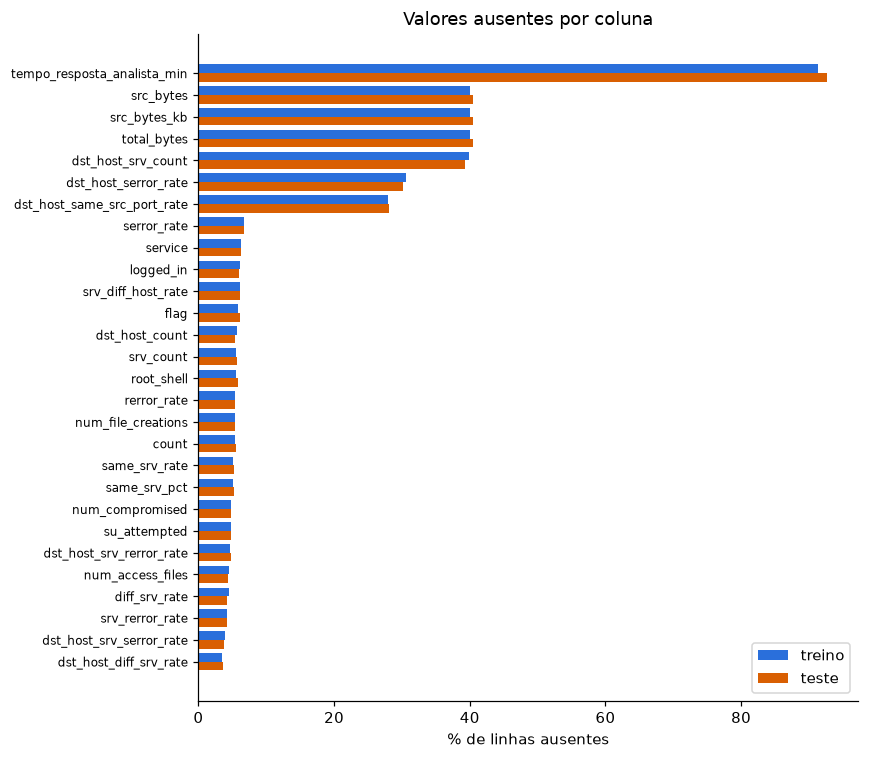

In [3]:
# Ausentes por coluna: treino x teste (em % das linhas)
aus = pd.DataFrame({
    "treino_n": treino.isna().sum(),
    "treino_%": treino.isna().mean() * 100,
    "teste_n": teste.isna().sum().reindex(treino.columns).astype("Int64"),
    "teste_%": teste.isna().mean().reindex(treino.columns) * 100,
})
aus = aus[(aus["treino_n"] > 0) | (aus["teste_n"] > 0)].sort_values("treino_%", ascending=False)
display(aus)
R["n_cols_com_ausente_treino"] = int((treino.isna().sum() > 0).sum())
R["n_cols_com_ausente_teste"] = int((teste.isna().sum() > 0).sum())
print("Colunas com ausentes no treino:", R["n_cols_com_ausente_treino"], "| no teste:", R["n_cols_com_ausente_teste"])
print("Maior diferença treino x teste (pontos percentuais):", round((aus['treino_%'] - aus['teste_%']).abs().max(), 2))

fig, ax = plt.subplots(figsize=(8, 7))
pos = np.arange(len(aus))
ax.barh(pos - 0.2, aus["treino_%"], 0.4, color=AZUL, label="treino")
ax.barh(pos + 0.2, aus["teste_%"].fillna(0), 0.4, color=LARANJA, label="teste")
ax.set_yticks(pos); ax.set_yticklabels(aus.index, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("% de linhas ausentes"); ax.set_title("Valores ausentes por coluna"); ax.legend()
plt.tight_layout(); plt.show()

In [4]:
# Ausentes por classe (só no treino, porque o teste não tem rótulo)
aus_cls = treino.drop(columns=ALVO).isna().groupby(treino[ALVO]).mean().T * 100
aus_cls = aus_cls[(aus_cls > 0).any(axis=1)]
aus_cls["diferença (anomaly - normal)"] = aus_cls["anomaly"] - aus_cls["normal"]
display(aus_cls.sort_values("diferença (anomaly - normal)", key=abs, ascending=False))

class,anomaly,normal,diferença (anomaly - normal)
tempo_resposta_analista_min,23.5352,95.5744,-72.0392
dst_host_serror_rate,44.8394,29.7533,15.0861
dst_host_same_src_port_rate,26.5261,28.0759,-1.5497
src_bytes,38.9556,40.0234,-1.0678
src_bytes_kb,38.9556,40.0234,-1.0678
total_bytes,38.9556,40.0234,-1.0678
num_file_creations,5.9573,5.3153,0.6421
count,4.7806,5.3670,-0.5864
dst_host_srv_rerror_rate,4.2167,4.7541,-0.5374
srv_diff_host_rate,5.6386,6.1091,-0.4705


**Como ler:** se a % de ausentes for parecida nas duas classes, a ausência é "aleatória" e basta imputar. Se for muito diferente, a *própria ausência* carrega informação sobre a classe — assunto da seção 6.

### Conclusão da seção 1

- Treino: 69.833 linhas × 50 colunas; teste: 24.333 × 50. O treino tem a coluna `class` e o teste tem a coluna `id`; fora isso, as colunas são as mesmas.
- Há 28 colunas com valores ausentes, tanto no treino quanto no teste, e as proporções são muito parecidas (diferença máxima de 1,24 pontos percentuais). Ou seja, **o teste foi "estragado" do mesmo jeito que o treino** quanto a ausentes.
- Algumas colunas têm muitos ausentes: `tempo_resposta_analista_min` (91,4% no treino), `src_bytes` (40,0%), `dst_host_srv_count` (39,9%), `dst_host_serror_rate` (30,6%) e `dst_host_same_src_port_rate` (28,0%). As demais ficam entre 3,5% e 6,8%.
- Por classe, a ausência é parecida para quase todas as colunas. Duas exceções: `tempo_resposta_analista_min` (23,5% ausente em `anomaly` contra 95,6% em `normal`) e `dst_host_serror_rate` (44,8% contra 29,8%).

**Para as próximas etapas:** será preciso imputar (dentro do pipeline, sem olhar o teste). As duas exceções acima precisam de atenção especial na seção 6.

## 2. Classes e desbalanceamento

Quantas conexões são `normal` e quantas são `anomaly`? Se uma classe for bem mais rara, a **acurácia engana** e a escolha de métrica e de validação importa muito.

,contagem,proporção (%)
class,,
normal,65754,94.1589
anomaly,4079,5.8411


Razão normal:anomaly = 16.1 : 1


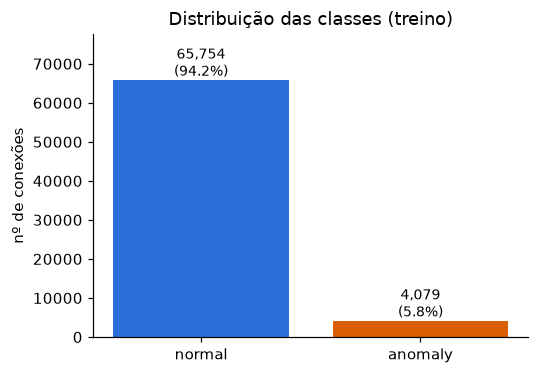

In [5]:
cont = treino[ALVO].value_counts()
prop = treino[ALVO].value_counts(normalize=True) * 100
tab_cls = pd.DataFrame({"contagem": cont, "proporção (%)": prop})
display(tab_cls)

R["pct_anomaly"] = float(prop["anomaly"]); R["pct_normal"] = float(prop["normal"])
R["razao"] = float(cont["normal"] / cont["anomaly"])
print(f"Razão normal:anomaly = {R['razao']:.1f} : 1")

fig, ax = plt.subplots(figsize=(5, 3.5))
barras = ax.bar(cont.index, cont.values, color=[AZUL, LARANJA])
for b, v, p in zip(barras, cont.values, prop.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({p:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, cont.max() * 1.18); ax.set_ylabel("nº de conexões"); ax.set_title("Distribuição das classes (treino)")
plt.tight_layout(); plt.show()

In [6]:
# Por que a acurácia engana: um "modelo" que diz sempre "normal"
pred_sempre_normal = np.zeros(len(y), dtype=int)
R["acc_baseline"] = accuracy_score(y, pred_sempre_normal)
R["f1macro_baseline"] = f1_score(y, pred_sempre_normal, average="macro")
print(f"Acurácia do 'sempre normal': {R['acc_baseline']:.4f}")
print(f"F1-macro do 'sempre normal': {R['f1macro_baseline']:.4f}")

# F1-macro = média do F1 de cada classe; a classe rara pesa tanto quanto a comum
print("F1 por classe:", dict(zip(["normal", "anomaly"], np.round(f1_score(y, pred_sempre_normal, average=None, zero_division=0), 4))))

Acurácia do 'sempre normal': 0.9416
F1-macro do 'sempre normal': 0.4850
F1 por classe: {'normal': np.float64(0.9699), 'anomaly': np.float64(0.0)}


**Implicações práticas**
- **Métrica:** o F1-macro calcula o F1 de cada classe e tira a média simples, então errar em `anomaly` custa tanto quanto errar em `normal`. O baseline acima mostra: alta acurácia, F1-macro baixo.
- **Validação:** usar divisão **estratificada** (mesma proporção de classes em cada fold), por exemplo `StratifiedKFold` com semente fixa, para que todo fold tenha exemplos suficientes de `anomaly`.
- **Treino:** vale considerar `class_weight="balanced"` ou reamostragem, e **ajustar o limiar de decisão** para maximizar o F1-macro. Reamostragem só dentro do treino de cada fold, nunca antes de separar a validação.

### Conclusão da seção 2

- Classes muito desbalanceadas: `normal` = 65.754 (94,2%) e `anomaly` = 4.079 (5,8%), uma razão de cerca de 16 para 1.
- Um "modelo" que sempre diz `normal` tem acurácia de 0,9416, mas F1-macro de apenas 0,4850 (F1 da classe `anomaly` = 0). Por isso a acurácia não serve; usaremos F1-macro, como a competição.

**Para as próximas etapas:** validação estratificada com semente fixa, ponderação de classes ou reamostragem *apenas dentro do treino de cada fold* e ajuste do limiar de decisão para o F1-macro.

## 3. Atributos categóricos: `protocol_type`, `service`, `flag`

Variáveis de texto costumam esconder sujeira: o mesmo valor escrito de formas diferentes (`tcp`, `TCP`, `tcp `) vira categorias distintas para o modelo. Verificamos (a) a cardinalidade, (b) grafias duplicadas e (c) se o teste usa as mesmas categorias do treino.

In [7]:
def norm(s):
    """Normaliza texto: tira espaços nas pontas e põe em minúsculas."""
    return s.str.strip().str.lower()

linhas = []
for col in ["protocol_type", "service", "flag"]:
    for nome, df in [("treino", treino), ("teste", teste)]:
        s = df[col].dropna()
        # forma "canônica" = grafia mais frequente de cada valor normalizado
        canon = s.groupby(norm(s)).agg(lambda v: v.value_counts().idxmax())
        fora = (s != norm(s).map(canon)).sum()
        linhas.append({"coluna": col, "base": nome, "ausentes": int(df[col].isna().sum()),
                       "distintos (bruto)": s.nunique(), "distintos (normalizado)": norm(s).nunique(),
                       "com espaço nas pontas": int((s != s.str.strip()).sum()),
                       "linhas fora da grafia canônica": int(fora)})
card = pd.DataFrame(linhas)
display(card)
R["card"] = card

,coluna,base,ausentes,distintos (bruto),distintos (normalizado),com espaço nas pontas,linhas fora da grafia canônica
0,protocol_type,treino,0,6,3,0,1455
1,protocol_type,teste,0,3,3,0,0
2,service,treino,4416,96,67,1292,1292
3,service,teste,1528,65,65,0,0
4,flag,treino,4093,19,11,0,1340
5,flag,teste,1483,11,11,0,0


In [8]:
# Quais grafias existem para o mesmo valor? (treino)
for col in ["protocol_type", "flag"]:
    print(f"--- {col}: contagem por grafia (treino) ---")
    print(treino[col].value_counts(dropna=False).to_string(), "\n")

s = treino["service"].dropna()
variantes = s.groupby(norm(s)).agg(lambda v: v.value_counts().to_dict())
variantes = variantes[variantes.map(len) > 1]
print(f"--- service: {len(variantes)} valores normalizados têm mais de uma grafia. Exemplos: ---")
print(variantes.head(8).to_string())

--- protocol_type: contagem por grafia (treino) ---
protocol_type
tcp     54824
udp     11940
icmp     1614
TCP      1186
UDP       240
ICMP       29 

--- flag: contagem por grafia (treino) ---
flag
SF        58058
NaN        4093
REJ        2856
S0         2399
sf         1220
RSTR        328
S1          288
RSTO        287
S2          103
rej          61
S3           52
s0           33
SH           19
rstr         10
OTH           8
s2            6
rsto          4
s1            4
s3            2
RSTOS0        2 

--- service: 29 valores normalizados têm mais de uma grafia. Exemplos: ---
service
auth                   {'auth': 227, 'auth ': 4}
bgp                       {'bgp': 35, 'bgp ': 2}
ctf                       {'ctf': 40, 'ctf ': 2}
domain_u    {'domain_u': 7497, 'domain_u ': 174}
eco_i                {'eco_i': 593, 'eco_i ': 8}
ecr_i                {'ecr_i': 341, 'ecr_i ': 1}
exec                    {'exec': 16, 'exec ': 1}
finger            {'finger': 557, 'finger ': 11}


In [9]:
# A grafia "estranha" está ligada à classe? (se estivesse, seria pista indevida)
s = treino["protocol_type"]
estranha = s.notna() & (s != s.str.lower())
print("protocol_type com maiúsculas (grafia fora do padrão), por classe:")
print(pd.crosstab(estranha, treino[ALVO], normalize="columns").mul(100).round(2).rename(index={True: "fora do padrão (%)", False: "padrão (%)"}))

# Treino x teste: categorias (já normalizadas) que aparecem só em um dos lados
for col in ["protocol_type", "service", "flag"]:
    a, b = set(norm(treino[col].dropna())), set(norm(teste[col].dropna()))
    print(f"\n{col}: só no teste = {sorted(b - a)} | só no treino = {len(a - b)} valores "
          f"({sorted(a - b)[:8]}{'...' if len(a - b) > 8 else ''})")
R["serv_so_teste"] = len(set(norm(teste['service'].dropna())) - set(norm(treino['service'].dropna())))

protocol_type com maiúsculas (grafia fora do padrão), por classe:
class               anomaly  normal
protocol_type                      
padrão (%)          97.7400 97.9300
fora do padrão (%)   2.2600  2.0700

protocol_type: só no teste = [] | só no treino = 0 valores ([])

service: só no teste = [] | só no treino = 2 valores (['http_2784', 'shell'])



flag: só no teste = [] | só no treino = 0 valores ([])


In [10]:
# Também no teste: a % de cada categoria é parecida com a do treino? (já normalizado)
for col in ["protocol_type", "flag"]:
    comp = pd.DataFrame({"treino_%": norm(treino[col]).value_counts(normalize=True) * 100,
                         "teste_%": norm(teste[col]).value_counts(normalize=True) * 100}).fillna(0)
    print(f"--- {col} ---"); display(comp)
top = norm(treino["service"]).value_counts(normalize=True).head(6) * 100
print("service — 6 mais frequentes no treino (%):"); print(top.round(2).to_string())
print("mesmos serviços no teste (%):"); print((norm(teste['service']).value_counts(normalize=True) * 100).reindex(top.index).round(2).to_string())

--- protocol_type ---


,treino_%,teste_%
protocol_type,,
tcp,80.2056,79.8422
udp,17.4416,17.8318
icmp,2.3528,2.3261


--- flag ---


,treino_%,teste_%
flag,,
oth,0.0122,0.0131
rej,4.4372,4.2101
rsto,0.4427,0.4070
rstos0,0.0030,0.0175
rstr,0.5141,0.4902
s0,3.6994,2.9978
s1,0.4442,0.4508
s2,0.1658,0.1663
s3,0.0821,0.0613


service — 6 mais frequentes no treino (%):
service
http       55.3600
domain_u   11.7300
smtp        9.2800
ftp_data    6.5300
private     4.5100
other       3.3200
mesmos serviços no teste (%):
service
http       54.9300
domain_u   12.2200
smtp        9.5200
ftp_data    6.9900
private     3.9700
other       3.5000


### Conclusão da seção 3

- **Treino sujo, teste limpo.** Em `protocol_type` há 6 grafias para 3 valores (`tcp/TCP`, `udp/UDP`, `icmp/ICMP`); em `flag`, 19 grafias para 11 valores (minúsculas); em `service`, 96 grafias para 67 valores, por causa de **espaço no fim** (1.292 linhas). No teste, `protocol_type` (3), `service` (65) e `flag` (11) já vêm sem variações.
- A grafia errada **não está ligada à classe** (2,26% das anomalias e 2,07% dos normais têm `protocol_type` em maiúsculas), então é ruído puro, não pista.
- Depois de normalizar (tirar espaços e pôr em minúsculas), o teste não tem nenhuma categoria que o treino não tenha. Só o treino tem 2 serviços a mais (`http_2784` e `shell`), e as frequências de `protocol_type`, `flag` e dos serviços mais comuns são parecidas nos dois conjuntos.

**Para as próximas etapas:** normalizar o texto com uma regra fixa (`strip` + `lower`) *antes* de codificar; usar codificação que tolere categorias raras ou desconhecidas. Sem essa limpeza, o modelo trataria `TCP` e `tcp` como protocolos diferentes e aprenderia pior.

## 4. Inconsistências nos valores

Aqui procuramos valores **impossíveis** pela natureza da variável:
- duração e bytes **não podem ser negativos**;
- taxas (`*_rate`) são proporções, logo devem estar em **[0, 1]**;
- `count` e `srv_count` vão até **511**; `dst_host_count` e `dst_host_srv_count` até **255**;
- `su_attempted` deveria ser **0 ou 1**;
- **linhas duplicadas** e **linhas idênticas com classes diferentes** (rótulos contraditórios).

Repetimos tudo no teste para ver se os problemas existem lá também.

In [11]:
LIMITES = {"count": 511, "srv_count": 511, "dst_host_count": 255, "dst_host_srv_count": 255}
sem_id = [c for c in teste.columns if c != "id"]

def conta_invalidos(df):
    out = {}
    for c in [c for c in NUM if c != "protocolo_cod"]:
        out[f"negativo: {c}"] = int((df[c] < 0).sum())
    for c in TAXAS:
        out[f"fora de [0,1]: {c}"] = int(((df[c] < 0) | (df[c] > 1)).sum())
    for c, m in LIMITES.items():
        out[f"acima de {m}: {c}"] = int((df[c] > m).sum())
    out["su_attempted fora de {0,1}"] = int((df["su_attempted"].notna() & ~df["su_attempted"].isin([0, 1])).sum())
    return pd.Series(out)

inv = pd.DataFrame({"treino": conta_invalidos(treino), "teste": conta_invalidos(teste)})
inv = inv[(inv > 0).any(axis=1)]
display(inv)
R["inv"] = inv
print("Total de ocorrências inválidas — treino:", int(inv['treino'].sum()), "| teste:", int(inv['teste'].sum()))

,treino,teste
negativo: duration,358,0
negativo: src_bytes,189,0
negativo: src_bytes_kb,189,0
negativo: total_bytes,73,0
"fora de [0,1]: rerror_rate",683,0
"fora de [0,1]: dst_host_same_srv_rate",670,0
"fora de [0,1]: dst_host_diff_srv_rate",623,0
"fora de [0,1]: dst_host_srv_diff_host_rate",739,0
"fora de [0,1]: dst_host_srv_rerror_rate",714,0
acima de 511: count,464,0


Total de ocorrências inválidas — treino: 6170 | teste: 18


In [12]:
# Como são os valores inválidos? Olhamos os valores mais frequentes para entender o "padrão" do erro.
def top_invalidos(nome, v, n=6):
    v = v.dropna()
    freq = v.value_counts().head(n)
    return {"coluna": nome, "n": len(v), "mín": v.min(), "máx": v.max(),
            "valores mais frequentes (valor: contagem)": ", ".join(f"{k:g}: {c}" for k, c in freq.items())}

linhas = []
for c in ["rerror_rate", "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_srv_diff_host_rate", "dst_host_srv_rerror_rate"]:
    linhas.append(top_invalidos(c + " (fora de [0,1])", treino[c][(treino[c] < 0) | (treino[c] > 1)]))
for c, m in LIMITES.items():
    linhas.append(top_invalidos(c + f" (>{m})", treino[c][treino[c] > m]))
for c in ["duration", "src_bytes"]:
    linhas.append(top_invalidos(c + " (<0)", treino[c][treino[c] < 0]))
with pd.option_context("display.max_colwidth", 80):
    display(pd.DataFrame(linhas).set_index("coluna"))

# Os valores válidos dessas colunas, para comparar a escala
print("Máximos 'normais' (percentil 99,9 dos valores válidos):")
print({c: round(float(treino.loc[treino[c].between(0, m), c].quantile(0.999)), 3) for c, m in LIMITES.items()})

,n,mín,máx,valores mais frequentes (valor: contagem)
coluna,,,,
"rerror_rate (fora de [0,1])",683,1.5000,10.0000,"1.5: 186, 2: 182, 5: 166, 10: 149"
"dst_host_same_srv_rate (fora de [0,1])",670,1.5000,10.0000,"1.5: 186, 5: 167, 10: 162, 2: 155"
"dst_host_diff_srv_rate (fora de [0,1])",623,1.5000,10.0000,"10: 175, 1.5: 155, 2: 147, 5: 146"
"dst_host_srv_diff_host_rate (fora de [0,1])",739,1.5000,10.0000,"5: 198, 1.5: 182, 2: 181, 10: 178"
"dst_host_srv_rerror_rate (fora de [0,1])",714,1.5000,10.0000,"1.5: 188, 5: 186, 10: 180, 2: 160"
count (>511),464,550.0000,"512,000.0000","2000: 79, 600: 18, 3000: 16, 5000: 12, 6000: 11, 4000: 11"
srv_count (>511),507,550.0000,"512,000.0000","2000: 62, 4000: 17, 600: 16, 800: 14, 3000: 14, 900: 13"
dst_host_count (>255),912,260.0000,"256,000.0000","25600: 112, 256000: 112, 2560: 84, 12800: 84, 3500: 10, 1000: 7"
dst_host_srv_count (>255),0,NaN,NaN,


Máximos 'normais' (percentil 99,9 dos valores válidos):
{'count': 511.0, 'srv_count': 511.0, 'dst_host_count': 255.0, 'dst_host_srv_count': 255.0}


In [13]:
# su_attempted: valores existentes (treino x teste)
print("su_attempted — treino:", treino["su_attempted"].value_counts(dropna=False).to_dict())
print("su_attempted — teste :", teste["su_attempted"].value_counts(dropna=False).to_dict())
r_tr = (treino["su_attempted"] == 2).sum() / treino["su_attempted"].notna().sum() * 100
r_te = (teste["su_attempted"] == 2).sum() / teste["su_attempted"].notna().sum() * 100
print(f"Proporção do valor 2 (entre não ausentes): treino {r_tr:.3f}% | teste {r_te:.3f}%")
print("Classe das linhas com su_attempted=2 (treino):", treino.loc[treino['su_attempted'] == 2, ALVO].value_counts().to_dict())

su_attempted — treino: {0.0: 66462, nan: 3306, 2.0: 49, 1.0: 16}
su_attempted — teste : {0.0: 23123, nan: 1183, 2.0: 18, 1.0: 9}
Proporção do valor 2 (entre não ausentes): treino 0.074% | teste 0.078%
Classe das linhas com su_attempted=2 (treino): {'normal': 49}


In [14]:
# Linhas duplicadas e linhas contraditórias (mesmos atributos, classes diferentes)
feat = [c for c in treino.columns if c != ALVO]
R["dup_completas"] = int(treino.duplicated().sum())                 # inclui a classe
R["dup_features"] = int(treino.duplicated(subset=feat).sum())       # só atributos
R["dup_teste"] = int(teste.duplicated(subset=sem_id).sum())
print("Duplicatas no treino (linha inteira, com classe):", R["dup_completas"])
print("Duplicatas no treino (só atributos):            ", R["dup_features"])
print("Duplicatas no teste (ignorando id):             ", R["dup_teste"])

h = pd.util.hash_pandas_object(treino[feat], index=False)            # "impressão digital" de cada linha
n_classes = treino.groupby(h)[ALVO].nunique()
grupos_conf = n_classes[n_classes > 1].index
R["conflito_grupos"] = len(grupos_conf)
R["conflito_linhas"] = int(h.isin(grupos_conf).sum())
print(f"Grupos de linhas idênticas com classes diferentes: {R['conflito_grupos']} (envolvem {R['conflito_linhas']} linhas)")

extra = treino.duplicated(subset=feat)            # cópias "extras" (a 2ª, 3ª... ocorrência)
print("\nClasse das cópias extras:", treino.loc[extra, ALVO].value_counts(normalize=True).mul(100).round(2).to_dict())
print("Classe das demais linhas:", treino.loc[~extra, ALVO].value_counts(normalize=True).mul(100).round(2).to_dict())

# Linhas do teste que são cópia exata de alguma linha do treino? (só comparação, nada é ajustado)
h_te = pd.util.hash_pandas_object(teste[feat].reset_index(drop=True), index=False)
R["teste_em_treino"] = int(h_te.isin(set(h)).sum())
print("Linhas do teste idênticas a alguma linha do treino:", R["teste_em_treino"])

Duplicatas no treino (linha inteira, com classe): 11355
Duplicatas no treino (só atributos):             13057
Duplicatas no teste (ignorando id):              0
Grupos de linhas idênticas com classes diferentes: 1702 (envolvem 3730 linhas)

Classe das cópias extras: {'normal': 89.16, 'anomaly': 10.84}
Classe das demais linhas: {'normal': 95.31, 'anomaly': 4.69}


Linhas do teste idênticas a alguma linha do treino: 0


**Por que duplicatas importam para a validação:** se a mesma linha cair no treino *e* na validação, o modelo "decora" e a nota fica otimista. A solução é remover duplicatas **antes** de dividir em folds.
Já linhas **contraditórias** (mesmos atributos, classes diferentes) são ruído de rótulo: nenhum modelo consegue acertar as duas.

### Conclusão da seção 4

- **O treino tem erros injetados; o teste praticamente não tem.** No treino foram 6.170 ocorrências inválidas contra 18 no teste, todas de `su_attempted`.
- Negativos (só no treino): `duration` (358, dos quais 323 são exatamente −1, parecendo um marcador de erro), `src_bytes` (189, e as colunas derivadas dele) e `total_bytes` (73).
- Taxas fora de [0, 1] (só no treino): entre 623 e 739 linhas em cada uma de 5 colunas, e os valores inválidos são sempre 1,5, 2, 5 ou 10. Contagens acima do máximo: `count` (464), `srv_count` (507) e `dst_host_count` (912), com valores "redondos" como 600, 2.000, 3.000 e até 512.000 (em `dst_host_count`, 25.600 e 256.000). Não parece um erro de escala único, então a ação mais segura é tratar como ausente.
- `su_attempted` = 2 aparece em 49 linhas do treino (0,074%) e 18 do teste (0,078%), proporção quase igual e todas `normal` no treino. Como o teste tem o mesmo padrão, **não parece erro injetado só no treino**; é uma característica da base.
- **Duplicatas:** 11.355 linhas repetidas por inteiro (13.057 considerando só os atributos), contra 0 no teste. As cópias extras têm mais anomalias (10,84%) do que as demais linhas (4,69%): se ficarem, o treino superestima as anomalias e a validação fica otimista.
- **Rótulos contraditórios:** 1.702 grupos de linhas idênticas com classes diferentes (3.730 linhas).
- Nenhuma linha do teste é cópia exata de linha do treino.

**Para as próximas etapas:** (1) normalizar texto; (2) converter valores impossíveis em ausentes e imputar; (3) remover duplicatas e linhas contraditórias **antes** de separar folds de validação.

## 5. Redundâncias

Colunas redundantes não acrescentam informação e podem atrapalhar (multicolinearidade, custo, importância "diluída"). Procuramos: (a) colunas **constantes**, (b) colunas que são **cópias ou transformações** de outras, (c) pares **altamente correlacionados**.

In [15]:
# (a) Constantes ou quase constantes (treino)
nun = treino.drop(columns=ALVO).nunique(dropna=True)
topo = treino.drop(columns=ALVO).apply(lambda s: s.value_counts(normalize=True, dropna=True).iloc[0] * 100)
const = pd.DataFrame({"valores distintos": nun, "% do valor mais comum": topo})
display(const[(const["valores distintos"] <= 1) | (const["% do valor mais comum"] > 99.5)])
R["constantes"] = list(const.index[const["valores distintos"] <= 1])
print("Constantes no treino:", R["constantes"], "| constantes no teste:", list(teste.nunique()[lambda s: s <= 1].index))

,valores distintos,% do valor mais comum
land,2,99.9857
wrong_fragment,3,99.8325
urgent,4,99.9914
num_failed_logins,5,99.8740
root_shell,2,99.7862
su_attempted,3,99.9023
num_file_creations,31,99.6914
num_shells,3,99.9513
num_outbound_cmds,1,100.0000
is_host_login,2,99.9971


Constantes no treino: ['num_outbound_cmds'] | constantes no teste: ['num_outbound_cmds', 'is_host_login']


In [16]:
# (b) Colunas novas são transformações exatas de outras?
def confere(nome, derivada, esperada):
    ok = derivada.notna() & esperada.notna()
    dif = (derivada[ok] - esperada[ok]).abs().max()
    mesma_aus = ((derivada.isna()) == (esperada.isna())).mean() * 100
    print(f"{nome:42s} diferença máx.: {dif:.2e} | linhas comparadas: {ok.sum():>6} | mesma ausência: {mesma_aus:.1f}%")
    return dif

confere("src_bytes_kb = src_bytes/1024", treino.src_bytes_kb, treino.src_bytes / 1024)
confere("dst_bytes_kb = dst_bytes/1024", treino.dst_bytes_kb, treino.dst_bytes / 1024)
confere("total_bytes = src_bytes + dst_bytes", treino.total_bytes, treino.src_bytes + treino.dst_bytes)
confere("same_srv_pct = same_srv_rate*100", treino.same_srv_pct, treino.same_srv_rate * 100)

# protocolo_cod x protocol_type (normalizado)
print("\nprotocolo_cod x protocol_type (normalizado):")
display(pd.crosstab(norm(treino.protocol_type), treino.protocolo_cod))

# Mesmas conferências no teste
print("Teste:")
confere("src_bytes_kb (teste)", teste.src_bytes_kb, teste.src_bytes / 1024)
confere("total_bytes (teste)", teste.total_bytes, teste.src_bytes + teste.dst_bytes)
confere("same_srv_pct (teste)", teste.same_srv_pct, teste.same_srv_rate * 100)
display(pd.crosstab(norm(teste.protocol_type), teste.protocolo_cod))

src_bytes_kb = src_bytes/1024              diferença máx.: 0.00e+00 | linhas comparadas:  41927 | mesma ausência: 100.0%
dst_bytes_kb = dst_bytes/1024              diferença máx.: 0.00e+00 | linhas comparadas:  69833 | mesma ausência: 100.0%
total_bytes = src_bytes + dst_bytes        diferença máx.: 0.00e+00 | linhas comparadas:  41927 | mesma ausência: 100.0%
same_srv_pct = same_srv_rate*100           diferença máx.: 0.00e+00 | linhas comparadas:  66262 | mesma ausência: 100.0%

protocolo_cod x protocol_type (normalizado):


protocolo_cod,0,1,2
protocol_type,,,
icmp,0,0,1643
tcp,56010,0,0
udp,0,12180,0


Teste:
src_bytes_kb (teste)                       diferença máx.: 0.00e+00 | linhas comparadas:  14474 | mesma ausência: 100.0%
total_bytes (teste)                        diferença máx.: 0.00e+00 | linhas comparadas:  14474 | mesma ausência: 100.0%
same_srv_pct (teste)                       diferença máx.: 0.00e+00 | linhas comparadas:  23067 | mesma ausência: 100.0%


protocolo_cod,0,1,2
protocol_type,,,
icmp,0,0,566
tcp,19428,0,0
udp,0,4339,0


Pares de atributos originais com |r| >= 0.90: 1


,coluna_a,coluna_b,r
0,serror_rate,srv_serror_rate,0.9729


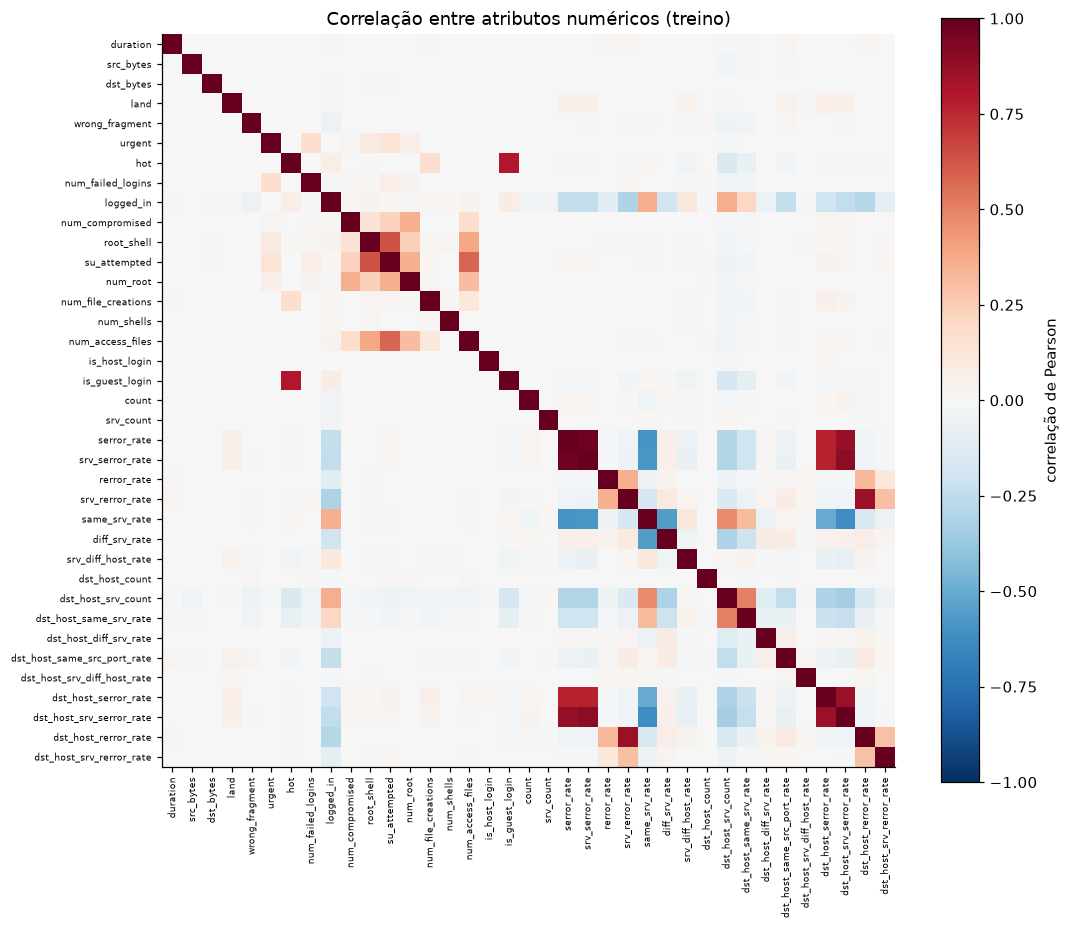

In [17]:
# (c) Correlação entre atributos numéricos (Pearson, pares completos). Ignoramos as colunas-cópia para ver só as "originais".
orig = [c for c in NUM if c not in ["src_bytes_kb", "dst_bytes_kb", "total_bytes", "same_srv_pct", "protocolo_cod",
                                     "score_ids_legado", "tempo_resposta_analista_min"] + R["constantes"]]
corr = treino[orig].corr()
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares = corr.where(mask).stack().rename("r").reset_index()
pares.columns = ["coluna_a", "coluna_b", "r"]
fortes = pares[pares["r"].abs() >= 0.90].sort_values("r", key=abs, ascending=False)
R["pares_fortes"] = len(fortes)
print(f"Pares de atributos originais com |r| >= 0.90: {len(fortes)}")
display(fortes.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(orig))); ax.set_xticklabels(orig, rotation=90, fontsize=6)
ax.set_yticks(range(len(orig))); ax.set_yticklabels(orig, fontsize=6)
fig.colorbar(im, ax=ax, label="correlação de Pearson"); ax.set_title("Correlação entre atributos numéricos (treino)")
plt.tight_layout(); plt.show()

### Conclusão da seção 5

- Constante: `num_outbound_cmds` (um único valor). No teste, `is_host_login` também é constante.
- As cópias foram confirmadas **exatamente** (diferença máxima 0 e mesma posição dos ausentes, no treino e no teste): `src_bytes_kb = src_bytes/1024`, `dst_bytes_kb = dst_bytes/1024`, `total_bytes = src_bytes + dst_bytes`, `same_srv_pct = same_srv_rate × 100`. E `protocolo_cod` é a codificação de `protocol_type` normalizado (tcp = 0, udp = 1, icmp = 2). Como `total_bytes` e `src_bytes_kb` herdam os ausentes de `src_bytes`, elas **não permitem recuperar** valores ausentes.
- Entre os atributos originais, só um par tem |r| ≥ 0,90: `serror_rate` e `srv_serror_rate` (r = 0,9729).

**Para as próximas etapas:** remover `num_outbound_cmds` e as 5 colunas-cópia, mantendo as originais; para modelos lineares, tratar o par de taxas `serror`; árvores toleram bem.

## 6. Possíveis vazamentos de dados (*data leakage*)

**Vazamento** acontece quando um atributo traz informação que **não estaria disponível na hora real da previsão** (ou que é quase o próprio rótulo). O modelo vai muito bem na validação e falha na vida real.

Fazemos três verificações:
1. **Pearson** de cada atributo com a classe (relações lineares);
2. **AUC de cada atributo sozinho** (pega relações *não lineares*; 0,5 = inútil, 1,0 = separa perfeitamente). Como o sentido não importa, usamos `max(AUC, 1−AUC)`;
3. **A falta de valor depende da classe?** (se sim, a ausência em si é uma pista).

Depois julgamos, coluna a coluna, **se ela existiria no momento da previsão**.

In [18]:
def auc_forte(x, alvo):
    """AUC do atributo sozinho, ignorando ausentes. Devolve (AUC bruta, AUC 'forte' = max(auc, 1-auc))."""
    ok = x.notna()
    if ok.sum() < 50 or alvo[ok].nunique() < 2 or x[ok].nunique() < 2:
        return np.nan, np.nan
    a = roc_auc_score(alvo[ok], x[ok])
    return a, max(a, 1 - a)

tipo_codif = (treino["tipo_alerta_soc"] == "ALERTA").astype(float).where(treino["tipo_alerta_soc"].notna())
X = treino[NUM].copy()
X["tipo_alerta_soc (ALERTA=1)"] = tipo_codif

rel = pd.DataFrame({
    "pearson": X.corrwith(y),
    "auc": {c: auc_forte(X[c], y)[0] for c in X.columns},
    "auc_forte": {c: auc_forte(X[c], y)[1] for c in X.columns},
    "% ausente": X.isna().mean() * 100,
})
rel["|pearson|"] = rel["pearson"].abs()
rel = rel.sort_values("auc_forte", ascending=False)
R["rel"] = rel
display(rel.head(20))

,pearson,auc,auc_forte,% ausente,|pearson|
tipo_alerta_soc (ALERTA=1),0.7282,0.9016,0.9016,0.0000,0.7282
score_ids_legado,0.5734,0.8829,0.8829,0.0000,0.5734
total_bytes,-0.0077,0.1566,0.8434,39.9610,0.0077
src_bytes_kb,0.0023,0.1760,0.8240,39.9610,0.0023
src_bytes,0.0023,0.1760,0.8240,39.9610,0.0023
dst_bytes,-0.0040,0.1833,0.8167,0.0000,0.0040
dst_bytes_kb,-0.0040,0.1833,0.8167,0.0000,0.0040
dst_host_srv_count,-0.3017,0.1923,0.8077,39.8723,0.3017
dst_host_same_srv_rate,-0.1940,0.2133,0.7867,0.0000,0.1940
same_srv_rate,-0.5225,0.2152,0.7848,5.1136,0.5225


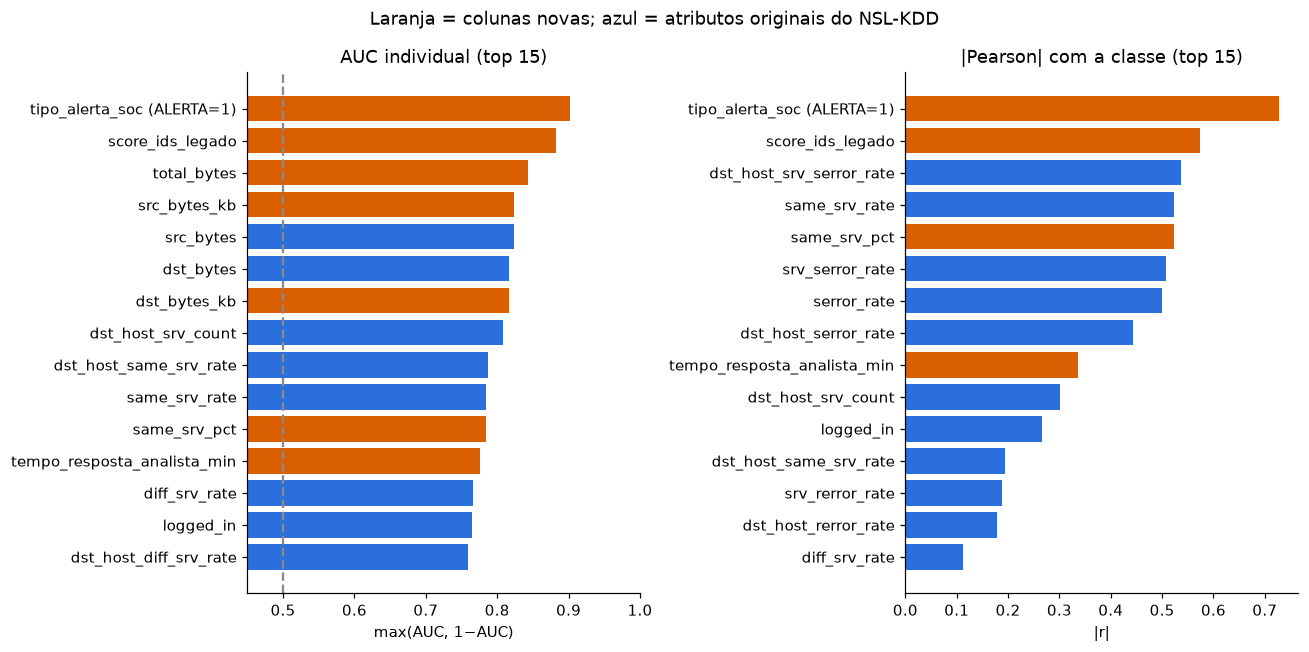

Maior AUC com |Pearson| baixo (<0.2) — relações não lineares:


,pearson,auc_forte,% ausente
total_bytes,-0.0077,0.8434,39.9610
src_bytes_kb,0.0023,0.8240,39.9610
src_bytes,0.0023,0.8240,39.9610
dst_bytes,-0.0040,0.8167,0.0000
dst_bytes_kb,-0.0040,0.8167,0.0000
dst_host_same_srv_rate,-0.1940,0.7867,0.0000
diff_srv_rate,0.1128,0.7654,4.4621
dst_host_diff_srv_rate,0.0300,0.7584,3.4511


In [19]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6), sharey=False)
top = rel.head(15).iloc[::-1]
cores = [LARANJA if c in NOVAS + ["tipo_alerta_soc (ALERTA=1)"] else AZUL for c in top.index]
axs[0].barh(top.index, top["auc_forte"], color=cores); axs[0].axvline(0.5, color=CINZA, ls="--")
axs[0].set_xlim(0.45, 1); axs[0].set_title("AUC individual (top 15)"); axs[0].set_xlabel("max(AUC, 1−AUC)")
top2 = rel.sort_values("|pearson|", ascending=False).head(15).iloc[::-1]
cores2 = [LARANJA if c in NOVAS + ["tipo_alerta_soc (ALERTA=1)"] else AZUL for c in top2.index]
axs[1].barh(top2.index, top2["|pearson|"], color=cores2); axs[1].set_title("|Pearson| com a classe (top 15)"); axs[1].set_xlabel("|r|")
fig.suptitle("Laranja = colunas novas; azul = atributos originais do NSL-KDD")
plt.tight_layout(); plt.show()

# Onde Pearson e AUC discordam (relação não linear / outliers)?
print("Maior AUC com |Pearson| baixo (<0.2) — relações não lineares:")
display(rel[rel["|pearson|"] < 0.2].sort_values("auc_forte", ascending=False).head(8)[["pearson", "auc_forte", "% ausente"]])

In [20]:
# As colunas novas: distribuição por classe
print("tipo_alerta_soc x classe (treino):")
display(pd.crosstab(treino["tipo_alerta_soc"], treino[ALVO], margins=True))
print("% de 'ALERTA' por classe:", (treino.groupby(ALVO)["tipo_alerta_soc"].apply(lambda s: (s == 'ALERTA').mean() * 100)).round(2).to_dict())
print("% de 'ALERTA' no treino:", round((treino['tipo_alerta_soc'] == 'ALERTA').mean() * 100, 2), "| no teste:", round((teste['tipo_alerta_soc'] == 'ALERTA').mean() * 100, 2))

print("\nscore_ids_legado por classe:")
display(treino.groupby(ALVO)["score_ids_legado"].describe())
print("score_ids_legado — teste:"); display(teste["score_ids_legado"].describe().to_frame().T)

print("\ntempo_resposta_analista_min: % preenchido por classe (treino):")
preench = treino.groupby(ALVO)["tempo_resposta_analista_min"].apply(lambda s: s.notna().mean() * 100)
print(preench.round(2).to_dict())
print("% preenchido — treino:", round(treino["tempo_resposta_analista_min"].notna().mean() * 100, 2),
      "| teste:", round(teste["tempo_resposta_analista_min"].notna().mean() * 100, 2))
print("Média do tempo (quando preenchido) por classe:", treino.groupby(ALVO)["tempo_resposta_analista_min"].mean().round(2).to_dict())

tipo_alerta_soc x classe (treino):


class,anomaly,normal,All
tipo_alerta_soc,,,
ALERTA,3379,1657,5036
OK,700,64097,64797
All,4079,65754,69833


% de 'ALERTA' por classe: {'anomaly': 82.84, 'normal': 2.52}
% de 'ALERTA' no treino: 7.21 | no teste: 5.92

score_ids_legado por classe:


,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
anomaly,"4,079.0000",0.7069,0.2998,0.0000,0.6730,0.8180,0.9040,1.0000
normal,"65,754.0000",0.1580,0.1742,0.0000,0.0570,0.1260,0.1990,1.0000


score_ids_legado — teste:


,count,mean,std,min,25%,50%,75%,max
score_ids_legado,"24,333.0000",0.1824,0.2142,0.0000,0.0580,0.1320,0.2100,1.0000



tempo_resposta_analista_min: % preenchido por classe (treino):
{'anomaly': 76.46, 'normal': 4.43}
% preenchido — treino: 8.63 | teste: 7.4
Média do tempo (quando preenchido) por classe: {'anomaly': 64.7, 'normal': 28.18}


In [21]:
# A FALTA de valor depende da classe? Teste qui-quadrado + AUC do indicador "está ausente"
linhas = []
for c in treino.columns.drop(ALVO):
    aus_c = treino[c].isna()
    if aus_c.sum() == 0:
        continue
    tabela = pd.crosstab(aus_c, treino[ALVO])
    p = chi2_contingency(tabela)[1]
    taxa = aus_c.groupby(treino[ALVO]).mean() * 100
    linhas.append({"coluna": c, "% ausente normal": taxa["normal"], "% ausente anomaly": taxa["anomaly"],
                   "diferença (pp)": taxa["anomaly"] - taxa["normal"], "p-valor": p,
                   "AUC do indicador": auc_forte(aus_c.astype(int), y)[1]})
miss = pd.DataFrame(linhas).set_index("coluna").sort_values("diferença (pp)", key=abs, ascending=False)
R["miss"] = miss
display(miss)
print("Colunas com diferença > 5 pontos percentuais:", list(miss.index[miss["diferença (pp)"].abs() > 5]))
print("Colunas com p < 0.001 mas diferença <= 5 pp (significativo mas pequeno):", list(miss.index[(miss['p-valor'] < 0.001) & (miss['diferença (pp)'].abs() <= 5)]))

,% ausente normal,% ausente anomaly,diferença (pp),p-valor,AUC do indicador
coluna,,,,,
tempo_resposta_analista_min,95.5744,23.5352,-72.0392,0.0000,0.8602
dst_host_serror_rate,29.7533,44.8394,15.0861,0.0000,0.5754
dst_host_same_src_port_rate,28.0759,26.5261,-1.5497,0.0339,0.5077
src_bytes,40.0234,38.9556,-1.0678,0.1820,0.5053
src_bytes_kb,40.0234,38.9556,-1.0678,0.1820,0.5053
total_bytes,40.0234,38.9556,-1.0678,0.1820,0.5053
num_file_creations,5.3153,5.9573,0.6421,0.0833,0.5032
count,5.3670,4.7806,-0.5864,0.1138,0.5029
dst_host_srv_rerror_rate,4.7541,4.2167,-0.5374,0.1255,0.5027


Colunas com diferença > 5 pontos percentuais: ['tempo_resposta_analista_min', 'dst_host_serror_rate']
Colunas com p < 0.001 mas diferença <= 5 pp (significativo mas pequeno): []


### Esta coluna existiria na hora da previsão?

O raciocínio é: imagine o sistema em produção. Chega uma conexão nova; o que já se sabe *naquele instante*?

| Coluna | Disponível na hora da previsão? | Raciocínio |
|---|---|---|
| 41 atributos originais (duração, bytes, flags, taxas de janela…) | **Sim** | São medidos a partir do tráfego da própria conexão e das conexões recentes. |
| `src_bytes_kb`, `dst_bytes_kb`, `total_bytes`, `same_srv_pct`, `protocolo_cod` | **Sim, mas redundantes** | Calculadas a partir de colunas que já existem (seção 5). Não vazam; só repetem. |
| `score_ids_legado` | **Duvidoso** | É a saída de *outro* detector. Se esse IDS roda em tempo real antes do nosso modelo, é usável; se foi gerado depois, é vazamento. Além disso, o modelo passaria a depender dele. Precisa ser confirmado com a professora. |
| `tipo_alerta_soc` | **Não (provável)** | "Alerta do SOC" é uma classificação feita por quem monitora/triagem, **depois** que algo chamou atenção. É praticamente uma resposta humana ao próprio problema que queremos prever. |
| `tempo_resposta_analista_min` | **Não** | O tempo que um analista levou para responder só existe **depois** que alguém investigou a conexão, e a investigação é muito mais frequente quando há anomalia (ver % preenchido por classe acima). A própria presença do valor entrega a classe. |

Mesmo que a coluna "exista" no teste desta competição, usá-la em um modelo real seria **trapaça**: o desempenho de validação não se repetiria em produção.

### Conclusão da seção 6

- **`tipo_alerta_soc`** é a coluna mais forte de todas (AUC 0,9016; correlação 0,7282): marca `ALERTA` em 82,84% das anomalias e só em 2,52% dos normais. É uma triagem humana feita depois do fato, portanto **vazamento provável**.
- **`tempo_resposta_analista_min`** só está preenchida em 76,46% das anomalias contra 4,43% dos normais; o AUC do simples "está ausente?" é 0,8602. A presença do valor entrega a classe, e ele só existe depois de uma investigação. **Vazamento claro**, tanto o valor quanto o indicador de ausência.
- **`score_ids_legado`** tem AUC 0,8829 (média 0,7069 nas anomalias e 0,1580 nos normais), sem ausentes. Pode ser legítima se o IDS legado rodar antes do nosso modelo; **é uma dúvida a esclarecer com a professora** e uma decisão a justificar.
- **Relações não lineares:** `src_bytes` (AUC 0,8240), `dst_bytes` (0,8167) e `total_bytes` (0,8434) têm correlação de Pearson praticamente zero (|r| < 0,01) mas AUC alto. Só a correlação os teria descartado; modelos de árvore ou transformação (por exemplo, logaritmo) aproveitam esses sinais.
- **Ausência × classe:** além de `tempo_resposta_analista_min`, só `dst_host_serror_rate` difere de forma relevante (44,84% ausente em `anomaly` contra 29,75% em `normal`, AUC do indicador 0,5754). Nas demais colunas a diferença é menor que 2 pontos percentuais e não é significativa (exceto `dst_host_same_src_port_rate`, com p = 0,034, diferença de 1,5 pp e pouco relevante na prática).
- As colunas `src_bytes_kb`, `dst_bytes_kb`, `total_bytes`, `same_srv_pct` e `protocolo_cod` estão disponíveis na hora da previsão, mas são redundantes; seus AUCs altos apenas repetem os das colunas originais.

**Para as próximas etapas:** remover `tempo_resposta_analista_min` e `tipo_alerta_soc`; decidir sobre `score_ids_legado` com a professora e comparar modelos com e sem ela; avaliar o indicador de ausência de `dst_host_serror_rate` por validação (ele existe no momento da previsão, mas pode ser um artefato da base).

## 7. Diagnóstico final

Resumo de cada achado, com a evidência (números calculados acima) e a **ação recomendada para a Etapa 2** (pré-processamento). Os números abaixo são preenchidos automaticamente a partir dos resultados guardados no dicionário `R`.

In [22]:
inv, rel, miss, card = R["inv"], R["rel"], R["miss"], R["card"]
n_neg = int(inv.loc[inv.index.str.startswith("negativo"), "treino"].sum())
n_taxa = int(inv.loc[inv.index.str.startswith("fora de [0,1]"), "treino"].sum())
n_cont = int(inv.loc[inv.index.str.startswith("acima de"), "treino"].sum())
n_su = int(inv.loc["su_attempted fora de {0,1}", "treino"]) if "su_attempted fora de {0,1}" in inv.index else 0
n_grafia = int(card[(card.base == "treino") & (card.coluna == "protocol_type")]["linhas fora da grafia canônica"].iloc[0])
n_grafia_flag = int(card[(card.base == "treino") & (card.coluna == "flag")]["linhas fora da grafia canônica"].iloc[0])
n_grafia_serv = int(card[(card.base == "treino") & (card.coluna == "service")]["linhas fora da grafia canônica"].iloc[0])
pre = treino.groupby(ALVO)["tempo_resposta_analista_min"].apply(lambda s: s.notna().mean() * 100)
alerta = treino.groupby(ALVO)["tipo_alerta_soc"].apply(lambda s: (s == "ALERTA").mean() * 100)
auc_score = rel.loc["score_ids_legado", "auc_forte"]
top_orig = rel.drop(index=[i for i in rel.index if i in NOVAS or "tipo_alerta" in i]).head(3)
teste_inv = lambda prefixo: int(inv.loc[inv.index.str.startswith(prefixo), "teste"].sum())

diag = [
 ("Desbalanceamento", f"anomaly = {R['pct_anomaly']:.1f}% ({R['razao']:.1f}:1); 'sempre normal' tem acurácia {R['acc_baseline']:.3f} e F1-macro {R['f1macro_baseline']:.3f}",
  "Validação estratificada; class_weight/limiar ajustado para F1-macro; nunca avaliar por acurácia."),
 ("Valores ausentes", f"{R['n_cols_com_ausente_treino']} colunas com NaN no treino e {R['n_cols_com_ausente_teste']} no teste, em proporções parecidas",
  "Imputar dentro do pipeline (mediana p/ numéricas, moda ou 'desconhecido' p/ texto), ajustando só no treino de cada fold."),
 ("Ausência que depende da classe", f"colunas com |dif.| > 5 pp: {list(miss.index[miss['diferença (pp)'].abs() > 5])}",
  "Não criar indicador de ausência para tempo_resposta_analista_min (vazamento). Avaliar indicador para dst_host_serror_rate."),
 ("Grafias duplicadas (texto)", f"linhas fora do padrão no treino: protocol_type {n_grafia}, flag {n_grafia_flag}, service {n_grafia_serv}; teste: ver tabela da seção 3",
  "Normalizar com strip() + lower() antes de codificar (regra determinística, sem 'fit')."),
 ("Categorias novas no teste", f"serviços só no teste (após normalizar): {R['serv_so_teste']}",
  "Codificação tolerante a categorias desconhecidas (handle_unknown='ignore'); agrupar serviços raros."),
 ("Valores negativos", f"{n_neg} ocorrências no treino (duration, src_bytes e derivadas); teste: {teste_inv('negativo')}",
  "Tratar como inválidos: converter em NaN e imputar (ou corrigir o sinal, após decisão justificada)."),
 ("Taxas fora de [0,1]", f"{n_taxa} ocorrências no treino; teste: {teste_inv('fora de [0,1]')}",
  "Converter em NaN e imputar (os valores 1,5/2/5/10 não parecem erro de escala simples)."),
 ("Contagens acima do máximo", f"{n_cont} ocorrências no treino (count/srv_count/dst_host_count); teste: {teste_inv('acima de')}",
  "Converter em NaN e imputar."),
 ("su_attempted = 2", f"{n_su} linhas no treino; proporção similar no teste",
  "Decidir entre recodificar 2→1 ou manter; o teste tem o mesmo padrão, então não é erro só do treino."),
 ("Duplicatas", f"treino: {R['dup_features']} cópias (só atributos); teste: {R['dup_teste']}",
  "Remover duplicatas do treino ANTES de dividir em folds."),
 ("Rótulos contraditórios", f"{R['conflito_grupos']} grupos de linhas idênticas com classes diferentes ({R['conflito_linhas']} linhas)",
  "Remover os grupos contraditórios (ou ficar com a classe majoritária) antes do treino."),
 ("Coluna constante", f"constante no treino: {R['constantes']}; no teste também is_host_login", "Remover num_outbound_cmds (e avaliar is_host_login, quase constante)."),
 ("Colunas-cópia", "src_bytes_kb, dst_bytes_kb, total_bytes, same_srv_pct e protocolo_cod são transformações exatas de outras colunas (seção 5)",
  "Remover as 5 (mantendo as originais) para evitar redundância e herdar menos erros."),
 ("Correlação alta entre originais", f"{R['pares_fortes']} pares com |r| ≥ 0,90",
  "Para modelos lineares, remover/regularizar; árvores toleram. Decidir por validação."),
 ("VAZAMENTO: tempo_resposta_analista_min", f"preenchido em {pre['anomaly']:.1f}% das anomalias vs {pre['normal']:.1f}% dos normais; só existe depois de investigação",
  "REMOVER (valor e indicador de ausência)."),
 ("VAZAMENTO provável: tipo_alerta_soc", f"'ALERTA' em {alerta['anomaly']:.1f}% das anomalias vs {alerta['normal']:.1f}% dos normais; é uma triagem humana pós-fato",
  "REMOVER."),
 ("Dependência: score_ids_legado", f"AUC individual {auc_score:.3f}; depende de outro detector",
  "Confirmar com a professora se existe em tempo real; comparar modelos com e sem, e reportar a diferença."),
 ("Atributos originais mais informativos", ", ".join(f"{i} (AUC {v:.3f})" for i, v in top_orig["auc_forte"].items()),
  "Manter; são candidatos naturais para o modelo."),
 ("Coluna id (teste)", "identificador, não é atributo", "Não usar como feature; só para montar a submissão."),
]
diagnostico = pd.DataFrame(diag, columns=["Achado", "Evidência", "Ação recomendada (Etapa 2)"])
with pd.option_context("display.max_colwidth", None):
    display(diagnostico.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))

Achado,Evidência,Ação recomendada (Etapa 2)
Desbalanceamento,anomaly = 5.8% (16.1:1); 'sempre normal' tem acurácia 0.942 e F1-macro 0.485,Validação estratificada; class_weight/limiar ajustado para F1-macro; nunca avaliar por acurácia.
Valores ausentes,"28 colunas com NaN no treino e 28 no teste, em proporções parecidas","Imputar dentro do pipeline (mediana p/ numéricas, moda ou 'desconhecido' p/ texto), ajustando só no treino de cada fold."
Ausência que depende da classe,"colunas com |dif.| > 5 pp: ['tempo_resposta_analista_min', 'dst_host_serror_rate']",Não criar indicador de ausência para tempo_resposta_analista_min (vazamento). Avaliar indicador para dst_host_serror_rate.
Grafias duplicadas (texto),"linhas fora do padrão no treino: protocol_type 1455, flag 1340, service 1292; teste: ver tabela da seção 3","Normalizar com strip() + lower() antes de codificar (regra determinística, sem 'fit')."
Categorias novas no teste,serviços só no teste (após normalizar): 0,Codificação tolerante a categorias desconhecidas (handle_unknown='ignore'); agrupar serviços raros.
Valores negativos,"809 ocorrências no treino (duration, src_bytes e derivadas); teste: 0","Tratar como inválidos: converter em NaN e imputar (ou corrigir o sinal, após decisão justificada)."
"Taxas fora de [0,1]",3429 ocorrências no treino; teste: 0,"Converter em NaN e imputar (os valores 1,5/2/5/10 não parecem erro de escala simples)."
Contagens acima do máximo,1883 ocorrências no treino (count/srv_count/dst_host_count); teste: 0,Converter em NaN e imputar.
su_attempted = 2,49 linhas no treino; proporção similar no teste,"Decidir entre recodificar 2→1 ou manter; o teste tem o mesmo padrão, então não é erro só do treino."
Duplicatas,treino: 13057 cópias (só atributos); teste: 0,Remover duplicatas do treino ANTES de dividir em folds.


### Conclusão final

A base de treino traz **três tipos de problema**: sujeira (grafias, negativos, valores fora do intervalo, duplicatas, rótulos contraditórios), **redundância** (5 colunas-cópia, 1 constante) e **vazamento** (`tempo_resposta_analista_min`, `tipo_alerta_soc` e a dúvida de `score_ids_legado`). O teste é muito mais limpo, então a limpeza será feita com regras fixas, decididas apenas com o treino, e a validação deve ser estratificada e sem duplicatas, usando o F1-macro. A Etapa 2 implementa a tabela acima.